# 01 - Data preparation and sanity checks

**Goal:** turn the raw Benzinga headline file into `data/processed/dataset.csv` with one row per
(headline, ticker): `published_at`, `ticker`, `headline`, `entry_date`, `abn_ret`, `label_up`.

Every step ends with a check, because the mistakes that make a backtest look good are almost always
made here (wrong timestamps, duplicated rows, leaked prices), not in the model.

| Step | Question the check answers |
|---|---|
| 1. Load | Is the schema what we think? Any missing values? |
| 2. Timestamps | Do the rows actually contain a time of day? Is the timezone sensible? |
| 3. Cleaning | How much do duplicates and generic roundup headlines distort the data? |
| 4. Alignment rule | Does the rule "when could this news be traded?" behave on hand-made edge cases? |
| 5. Returns | Is the abnormal return computed correctly, and what does its distribution look like? |
| 6. Sample + build | Did joining news to prices lose rows or introduce weekends / look-ahead? |
| 7. Statistics | Is the label balanced? How small an edge could this sample even detect? |
| 8. Rule comparison | What does the conservative date-only rule cost us? |

In [1]:
import sys; sys.path.append('..')
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import yfinance as yf

from src.data_prep import entry_date, build_dataset

SEED = 42
np.random.seed(SEED)

RAW, PROCESSED = Path('../data/raw'), Path('../data/processed')
BENZINGA = RAW / 'raw_analyst_ratings.jsonl'

# Study window. The file runs 2009-2020, but real time-of-day stamps are rare before 2019 (see step 2),
# and a short window keeps the daily cross-section dense enough for the quintile backtest later.
START, END = pd.Timestamp('2018-01-01'), pd.Timestamp('2020-06-10')
N_TICKERS = 100          # tickers kept in the final sample
MAX_PER_TICKER = 300     # cap per ticker -> at most 30k headlines (keeps LLM cost bounded)

## 1. Load and check the schema

In [2]:
raw = pd.read_json(BENZINGA, lines=True, dtype=False)
raw = raw.rename(columns={'stock': 'ticker', 'date': 'date_raw'})[['headline', 'ticker', 'date_raw', 'publisher']]
print('rows:', len(raw), '| tickers:', raw['ticker'].nunique())
display(raw.head(3))
display(raw.isna().sum().to_frame('n_missing').T)
assert raw[['headline', 'ticker', 'date_raw']].notna().all().all(), 'unexpected missing values'

rows: 1407328 | tickers: 6204


,headline,ticker,date_raw,publisher
0,Stocks That Hit 52-Week Highs On Friday,A,2020-06-05 10:30:54-04:00,Benzinga Insights
1,Stocks That Hit 52-Week Highs On Wednesday,A,2020-06-03 10:45:20-04:00,Benzinga Insights
2,71 Biggest Movers From Friday,A,2020-05-26 04:30:07-04:00,Lisa Levin


,headline,ticker,date_raw,publisher
n_missing,0,0,0,0


## 2. Timestamp quality

The whole project depends on knowing **when news became public**. Two things to verify:

1. Does the row carry a real time of day, or only a date? A date-only row is stored as `00:00:00`.
2. For rows that do have a time, is the timezone plausible?
   The market is open 09:30-16:00 US/Eastern, so real news times should cluster around those hours.

In [3]:
has_offset = raw['date_raw'].str.contains(r'[+-]\d\d:\d\d$')
raw['time_known'] = has_offset                       # strings with an explicit UTC offset carry a real time
raw['published_at'] = pd.to_datetime(raw['date_raw'], utc=True, format='mixed')   # naive strings are read as UTC midnight

print(f'rows with a real time of day: {has_offset.sum():,} ({has_offset.mean():.1%})')
print(f'date-only rows              : {(~has_offset).sum():,} ({(~has_offset).mean():.1%})')

# every date-only row must be exactly midnight, otherwise our "date-only" reading is wrong
naive_times = raw.loc[~has_offset, 'date_raw'].str[-8:]
assert (naive_times == '00:00:00').all(), 'a naive timestamp is not midnight'
print('offsets seen on timestamped rows:', raw.loc[has_offset, 'date_raw'].str[-6:].value_counts().to_dict())

ts = raw[has_offset].copy()
ts['et'] = ts['published_at'].dt.tz_convert('US/Eastern')
print('\ntimestamped rows per year:', ts['published_at'].dt.year.value_counts().sort_index().to_dict())

rows with a real time of day: 55,987 (4.0%)
date-only rows              : 1,351,341 (96.0%)


offsets seen on timestamped rows: {'-04:00': 55987}

timestamped rows per year: {2011: 760, 2012: 1181, 2013: 1246, 2014: 1189, 2015: 3695, 2016: 4223, 2017: 3581, 2018: 5395, 2019: 6325, 2020: 28392}


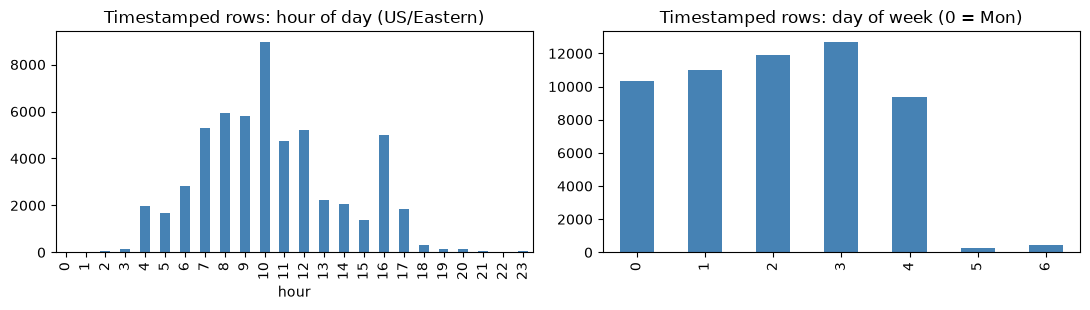

timestamped rows dated Dec-Feb: 10,102 (18.0%)
share by session: {'market hours': 0.488, 'before open': 0.376, 'after close': 0.136}


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ts['et'].dt.hour.value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue')
ax[0].set_title('Timestamped rows: hour of day (US/Eastern)'); ax[0].set_xlabel('hour')
ts['et'].dt.day_of_week.value_counts().sort_index().plot.bar(ax=ax[1], color='steelblue')
ax[1].set_title('Timestamped rows: day of week (0 = Mon)'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

# Fixed offset check: the source labels every time "-04:00". US Eastern is -04:00 only during daylight saving
# (roughly Mar-Nov) and -05:00 in winter. If winter rows also say -04:00 the label is a fixed offset and a
# winter time could be a full hour off. This matters only for news near the 16:00 cut-off.
winter = ts['et'].dt.month.isin([12, 1, 2])
print(f'timestamped rows dated Dec-Feb: {winter.sum():,} ({winter.mean():.1%})')

# Do the times look like Eastern wall-clock times? Share of rows per trading session:
minutes = ts['et'].dt.hour * 60 + ts['et'].dt.minute
session = pd.cut(minutes, [-1, 9 * 60 + 29, 16 * 60 - 1, 24 * 60], labels=['before open', 'market hours', 'after close'])
print('share by session:', session.value_counts(normalize=True).round(3).to_dict())

**Reading the result.** Most rows only know the calendar date, so for those we cannot say whether the news came
before or after the closing bell. That is handled explicitly in step 4. The timestamped rows are few, but they are
useful as a small high-quality subset (step 8).

### Is the `-04:00` label trustworthy? (checked after the fact)

Every timestamp in the source says `-04:00`, but US Eastern time is `-05:00` in winter. There are two possible explanations:

- **A) The source converted everything to a fixed UTC-4 clock.** Then the label is a true offset, the instant is right, and
  converting to `US/Eastern` (which is what `entry_date` does) gives the correct wall-clock time. The *printed* hours would be
  one hour later in winter than in summer.
- **B) The source printed Eastern wall-clock time and just attached `-04:00`.** Then winter times would be one hour off after our conversion.

Test: news follows the trading day, so its hour-of-day profile should look the same in winter and summer in *true* Eastern time.
Under A, the busiest printed hour differs by one between seasons and the converted hour agrees. Under B it would be the other way round.

In [ ]:
ts['printed_hour'] = pd.to_datetime(ts['date_raw'].str[:19]).dt.hour      # the clock time as printed, offset ignored
ts['month'] = ts['et'].dt.month
seasons = {'winter (Dec-Feb)': ts['month'].isin([12, 1, 2]), 'summer (Jun-Aug)': ts['month'].isin([6, 7, 8])}
rows = {}
for name, m in seasons.items():
    rows[f'{name}, printed'] = ts.loc[m, 'printed_hour'].value_counts(normalize=True).sort_index() * 100
    rows[f'{name}, converted to US/Eastern'] = ts.loc[m, 'et'].dt.hour.value_counts(normalize=True).sort_index() * 100
hours = pd.DataFrame(rows).fillna(0).loc[4:19].round(1)
display(hours.T)
peak = hours.idxmax()
print('busiest hour:', peak.to_dict())
assert peak['winter (Dec-Feb), printed'] - peak['summer (Jun-Aug), printed'] == 1       # explanation A predicts a 1h shift in printed time
assert peak['winter (Dec-Feb), converted to US/Eastern'] == peak['summer (Jun-Aug), converted to US/Eastern']   # and none after converting

,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
"winter (Dec-Feb), printed",0.3,3.7,2.7,4.7,6.7,9.1,8.2,19.4,10.3,8.2,4.8,4.2,2.7,9.8,3.3,0.7
"winter (Dec-Feb), converted to US/Eastern",3.7,2.7,4.7,6.7,9.1,8.2,19.4,10.3,8.2,4.8,4.2,2.7,9.8,3.3,0.7,0.3
"summer (Jun-Aug), printed",3.0,2.9,4.7,10.2,10.7,10.5,18.3,7.7,7.0,5.0,4.1,3.2,7.3,3.0,0.6,0.4
"summer (Jun-Aug), converted to US/Eastern",3.0,2.9,4.7,10.2,10.7,10.5,18.3,7.7,7.0,5.0,4.1,3.2,7.3,3.0,0.6,0.4


busiest hour: {'winter (Dec-Feb), printed': 11, 'winter (Dec-Feb), converted to US/Eastern': 10, 'summer (Jun-Aug), printed': 10, 'summer (Jun-Aug), converted to US/Eastern': 10}


**Result: explanation A.** The busiest printed hour is 11 in winter and 10 in summer, and after converting to `US/Eastern` both
peak at 10, with the pre-4pm spike at 16 in both seasons. So the `-04:00` label is a genuine fixed offset, our conversion is right, and
the one-hour worry in the earlier version of this notebook does not apply. This is a distribution check, not a proof for every
single row, but with 22 timestamped sampled rows within an hour of the cut-off (only 1 of them dated before March 8) it cannot matter much here.

## 3. Cleaning

Three things inflate the row count without adding information:

- **Exact duplicates** (same ticker and headline).
- **Generic roundup headlines** such as *"Stocks That Hit 52-Week Highs On Friday"*. They are attached to
  hundreds of tickers, say nothing specific about any one company, and would make the LLM and FinBERT read the
  same sentence thousands of times.
- Rows outside the study window.

In [5]:
steps = [('raw', len(raw))]

df = raw[(raw['published_at'] >= START.tz_localize('UTC')) & (raw['published_at'] <= END.tz_localize('UTC'))]
steps.append(('inside study window', len(df)))

df = df.drop_duplicates(['ticker', 'headline'])
steps.append(('drop exact duplicates', len(df)))

ROUNDUP = (r"Stocks (?:That )?Hit(?:ting)? 52-Week|Stocks Which Set New|New 52-Week|Top (?:Upgrades|Downgrades|Initiations)|"
           r"Biggest (?:Price Target Changes|Movers)|Market (?:Losers|Movers|Gainers)|Volume Movers|Pre-?Market|Mid-?Day|"
           r"Before The Trading Starts|Stocks Moving|Movers|Gainers|Losers|Earnings Scheduled|Earnings Preview")
is_roundup = df['headline'].str.contains(ROUNDUP, case=False, regex=True)
print('most common headlines removed by the regex:')
display(df.loc[is_roundup, 'headline'].value_counts().head(6).to_frame('n'))
df = df[~is_roundup]
steps.append(('drop roundups (regex)', len(df)))

# Safety net that does not depend on guessing wording: a headline attached to many different tickers cannot be
# about one company. The threshold (20 tickers) is a judgement call; the table shows what it catches.
tickers_per_headline = df.groupby('headline')['ticker'].nunique()
generic = df['headline'].map(tickers_per_headline) >= 20
print('\nadditionally removed because the identical headline sits on >= 20 tickers:')
display(df.loc[generic, 'headline'].value_counts().head(6).to_frame('n'))
df = df[~generic]
steps.append(('drop headlines on >= 20 tickers', len(df)))

display(pd.DataFrame(steps, columns=['step', 'rows']).assign(removed=lambda t: -t['rows'].diff()))
print(f'rows with a real time of day after cleaning: {df["time_known"].sum():,} ({df["time_known"].mean():.1%})')

most common headlines removed by the regex:


,n
headline,
Stocks That Hit 52-Week Lows On Thursday,2194
Stocks That Hit 52-Week Lows On Friday,1289
Stocks That Hit 52-Week Highs On Friday,1122
Stocks That Hit 52-Week Highs On Thursday,1081
Stocks That Hit 52-Week Highs On Tuesday,1058
Stocks That Hit 52-Week Lows On Wednesday,1002



additionally removed because the identical headline sits on >= 20 tickers:


,n
headline,
Benzinga Pro's 5 Stocks To Watch Today,282
Stocks That Fell Through 52-Week Lows Wednesday,207
"Stocks Trading Ex Dividend For Thurs., Sep. 13, 2018",163
"Stocks That Will Be Trading Ex Dividend Thurs., Dec. 13, 2018",140
Companies That Achieved 52-Week Highs Friday,136
A Peek Into The Markets: US Stock Futures Signal Higher Start On Wall Street,133


,step,rows,removed
0,raw,1407328,NaN
1,inside study window,401167,1006161.0
2,drop exact duplicates,386061,15106.0
3,drop roundups (regex),278398,107663.0
4,drop headlines on >= 20 tickers,252529,25869.0


rows with a real time of day after cleaning: 21,315 (8.4%)


Two caveats. (1) Both rules are heuristics, so the removed-headline tables above are the check that they did not
throw away real company news. (2) The share of timestamped rows is small after cleaning, because most
timestamped Benzinga rows were roundup posts. That decides how much of the project can use exact news times.

## 4. The alignment rule: when could this news be traded?

Let $t_{\text{news}}$ be the publication time and $C_d$ the closing price on trading day $d$.
We only ever trade at a close, so the **entry day** $e$ is the first close that is *certainly after* the news:

$$
e =
\begin{cases}
\text{that same day } d & \text{if the time is known and } t_{\text{news}} < 16{:}00 \text{ ET on a business day}\\
\text{next business day} & \text{if the time is known and } t_{\text{news}} \ge 16{:}00 \text{ ET}\\
\text{next business day} & \text{if only the date is known (it might have been after the close)}\\
\text{next Monday} & \text{if the news is on a weekend}
\end{cases}
$$

The target is the **abnormal return** from the entry close to the following close:

$$
r_{i,e} = \frac{C_{i,e+1}}{C_{i,e}} - 1, \qquad
AR_{i,e} = r_{i,e} - r_{\text{SPY},e}, \qquad
y_{i,e} = \mathbb{1}[AR_{i,e} > 0].
$$

Subtracting SPY removes the part of the move that the whole market shared. This is the simple *market-adjusted*
model (beta fixed at 1) and is a simplification of a proper market model $r_i = \alpha + \beta r_m + \varepsilon$;
it is good enough for a first test, but it will not remove, for example, the extra variation of a high-beta stock.

Before trusting the function, test it on hand-made cases where the right answer is obvious.

In [6]:
def et(s):   # helper: build a timezone-aware timestamp from a US/Eastern wall-clock string
    return pd.Timestamp(s, tz='US/Eastern').tz_convert('UTC')

cases = [
    # (description,                         timestamp,                         time_known, expected entry day)
    ('Fri 15:59 ET           -> same day',   et('2019-06-07 15:59'),            True,  '2019-06-07'),
    ('Fri 16:00 ET           -> Monday',     et('2019-06-07 16:00'),            True,  '2019-06-10'),
    ('Fri 23:30 ET           -> Monday',     et('2019-06-07 23:30'),            True,  '2019-06-10'),
    ('Sat noon               -> Monday',     et('2019-06-08 12:00'),            True,  '2019-06-10'),
    ('Mon 06:00 pre-market   -> same day',   et('2019-06-10 06:00'),            True,  '2019-06-10'),
    ('winter Tue 15:30 ET    -> same day',   et('2019-01-08 15:30'),            True,  '2019-01-08'),
    ('winter Tue 16:30 ET    -> Wednesday',  et('2019-01-08 16:30'),            True,  '2019-01-09'),
    ('date-only Mon          -> Tuesday',    pd.Timestamp('2019-06-10', tz='UTC'), False, '2019-06-11'),
    ('date-only Fri          -> Monday',     pd.Timestamp('2019-06-07', tz='UTC'), False, '2019-06-10'),
    ('date-only Sat          -> Monday',     pd.Timestamp('2019-06-08', tz='UTC'), False, '2019-06-10'),
]
rows = []
for name, t, known, expected in cases:
    got = entry_date(t, known)
    rows.append((name, str(got.date()), expected, str(got.date()) == expected))
res = pd.DataFrame(rows, columns=['case', 'got', 'expected', 'ok'])
display(res)
assert res['ok'].all(), 'alignment rule failed a hand-made case'
print('all', len(res), 'alignment cases pass')

,case,got,expected,ok
0,Fri 15:59 ET -> same day,2019-06-07,2019-06-07,True
1,Fri 16:00 ET -> Monday,2019-06-10,2019-06-10,True
2,Fri 23:30 ET -> Monday,2019-06-10,2019-06-10,True
3,Sat noon -> Monday,2019-06-10,2019-06-10,True
4,Mon 06:00 pre-market -> same day,2019-06-10,2019-06-10,True
5,winter Tue 15:30 ET -> same day,2019-01-08,2019-01-08,True
6,winter Tue 16:30 ET -> Wednesday,2019-01-09,2019-01-09,True
7,date-only Mon -> Tuesday,2019-06-11,2019-06-11,True
8,date-only Fri -> Monday,2019-06-10,2019-06-10,True
9,date-only Sat -> Monday,2019-06-10,2019-06-10,True


all 10 alignment cases pass


## 5. Prices and abnormal returns

Choose the tickers first: take the most-covered tickers in the window and keep those that Yahoo Finance actually
has prices for (delisted names are missing). Taking the **most-covered** tickers biases the sample toward large,
well-followed companies. That is a limitation to state in the write-up: results may not carry over to small caps.

In [7]:
SKIP = {'SPY'}                                   # SPY is the benchmark, its own abnormal return is zero by construction
counts = df['ticker'].value_counts()
candidates = [t for t in counts.index if t not in SKIP][:150]
print('candidate tickers:', len(candidates), '| headlines per candidate (median):', int(counts[candidates].median()))

px = yf.download(candidates + ['SPY'], start=START - pd.Timedelta(days=10), end=END + pd.Timedelta(days=15),
                 auto_adjust=True, progress=False)['Close']
px.index = px.index.tz_localize(None) if px.index.tz is not None else px.index
print('price table:', px.shape, '| SPY trading days:', px['SPY'].notna().sum())

in_window = px.loc[START:END]
coverage = in_window[candidates].notna().mean()           # share of SPY-like trading days with a price
display(coverage.describe().to_frame('coverage').T.round(3))

candidate tickers: 150 | headlines per candidate (median): 396


$OSTK: possibly delisted; no timezone found


$SAVE: possibly delisted; no timezone found


$FL: possibly delisted; no timezone found


$FB: Data doesn't exist for startDate = 1513918800, endDate = 1593057600


$JWN: possibly delisted; no timezone found


... (17 outputs left out)

['OSTK', 'SAVE', 'FL', 'JWN', 'DISH', 'X', 'RSX', 'GRUB', 'WBA', 'GWPH', 'MYL', 'AGN', 'GPS', 'FCAU', 'VMW', 'SPLK', 'ATVI']: possibly delisted; no timezone found


['FB', 'EA', 'BBBY']: Data doesn't exist for startDate = 1513918800, endDate = 1593057600


price table: (629, 151) | SPY trading days: 629


,count,mean,std,min,25%,50%,75%,max
coverage,150.0,0.857,0.344,0.0,1.0,1.0,1.0,1.0


In [8]:
good = coverage[coverage >= 0.98].index.tolist()
dropped = sorted(set(candidates) - set(good))
print(f'{len(good)} of {len(candidates)} candidates have >=98% price coverage')
print('dropped for missing prices:', dropped)

# Penny-stock filter: for a sub-penny stock one tick is a huge percentage move, so returns are mostly tick-size noise
# (e.g. HMNY, price ~$0.0002, showed "+200%" days). The literature usually excludes stocks under $1-$5.
# BUT: Yahoo prices are adjusted to TODAY'S share counts, so a stock that split later looks cheaper in 2018 than it
# really was (GME did a 4:1 split in 2022, so its 2019 price shows as < $1 although it traded around $3-$4).
# A $1 rule would wrongly drop such stocks, so I use a much lower floor that only catches true sub-penny cases.
PRICE_FLOOR = 0.10
min_price = in_window[good].min()
penny = min_price[min_price < PRICE_FLOOR].index.tolist()
print(f'excluded (adjusted price ever < ${PRICE_FLOOR}):', penny)

tickers = [t for t in candidates if t in good and t not in penny][:N_TICKERS]
print(f'keeping the top {len(tickers)} tickers by headline count')

127 of 150 candidates have >=98% price coverage
dropped for missing prices: ['AGN', 'AMTD', 'ATVI', 'BBBY', 'DISH', 'EA', 'FB', 'FCAU', 'FL', 'FOXA', 'GPS', 'GRUB', 'GWPH', 'JWN', 'MYL', 'NIO', 'OSTK', 'RSX', 'SAVE', 'SPLK', 'VMW', 'WBA', 'X']
excluded (adjusted price ever < $0.1): ['HMNY']
keeping the top 100 tickers by headline count


**Survivorship bias (important).** The dropped tickers are mostly companies that were acquired, delisted, went bankrupt
or were renamed after 2020 (e.g. `BBBY`, `GRUB`, `ATVI`, `FB`), because Yahoo Finance no longer serves their history.
Our sample therefore contains only companies that **survived**, and the worst outcomes (bankruptcy news) are
under-represented. This can flatter any strategy and has to be listed as a limitation in the write-up.

### Check the return computation independently

Compute one return by hand from raw prices and compare with the pipeline (`src/data_prep.py`) later in step 6.
Then look at the **distribution** of $AR$, because the backtest is sensitive to its shape:

- The mean should be close to 0 (we subtracted the market).
- Daily stock returns are **fat tailed**: kurtosis well above 3 (a normal distribution has 3).
  Extreme values may be real events or data errors such as unadjusted splits, so list them.

ticker-days: 61,400


,mean,std,skew,excess kurtosis,min,max
abnormal return,-0.0001,0.0215,1.6277,94.5464,-0.5175,0.7454


H0: mean AR = 0  ->  t = -0.68, p = 0.496

largest |AR| (check these are real events, not split / data errors):


,,|AR|
Date,Ticker,
2019-01-23,PCG,0.745401
2020-03-02,INO,0.725671
2019-01-11,PCG,0.517492
2020-03-10,INO,0.517169
2020-03-09,INO,0.471887
2020-03-05,INO,0.454287


share of ticker-days with |AR| > 10%: 0.585%


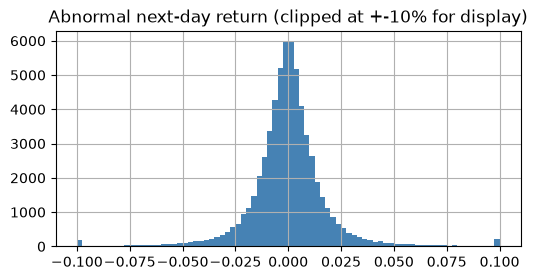

In [9]:
ret = px.pct_change(fill_method=None).shift(-1)          # row d holds C(d+1)/C(d) - 1
ar = ret[tickers].sub(ret['SPY'], axis=0).loc[START:END].stack().dropna()
print(f'ticker-days: {len(ar):,}')

summary = pd.Series({
    'mean': ar.mean(), 'std': ar.std(), 'skew': stats.skew(ar), 'excess kurtosis': stats.kurtosis(ar),
    'min': ar.min(), 'max': ar.max(),
})
display(summary.to_frame('abnormal return').T.map('{:.4f}'.format))

t_stat, p_val = stats.ttest_1samp(ar, 0.0)
print(f'H0: mean AR = 0  ->  t = {t_stat:.2f}, p = {p_val:.3f}')

print('\nlargest |AR| (check these are real events, not split / data errors):')
display(ar.abs().sort_values(ascending=False).head(6).to_frame('|AR|'))
print(f'share of ticker-days with |AR| > 10%: {(ar.abs() > 0.10).mean():.3%}')

ar.clip(-0.1, 0.1).hist(bins=80, figsize=(6, 2.8), color='steelblue'); plt.title('Abnormal next-day return (clipped at +-10% for display)'); plt.show()

## 6. Sample headlines and build the dataset

For each chosen ticker, keep at most `MAX_PER_TICKER` headlines (random, fixed seed). The sample stays in memory as a
DataFrame and goes straight into `build_dataset()` together with the price table we already downloaded in step 5,
so there is no CSV round trip (which would turn the `time_known` flags and timezones back into text) and no second
download. The files are written once, at the end.

In [10]:
# shuffle once with a fixed seed, then keep the first MAX_PER_TICKER rows of each ticker (= a random subset).
# (groupby().apply() is avoided on purpose: pandas 3 drops the grouping column from its result.)
sample = (df[df['ticker'].isin(tickers)]
          .sample(frac=1, random_state=SEED)
          .groupby('ticker').head(MAX_PER_TICKER))
sample = sample[['published_at', 'ticker', 'headline', 'time_known']].sort_values('published_at').reset_index(drop=True)
print('sampled headlines:', len(sample), '| tickers:', sample['ticker'].nunique())
display(sample['ticker'].value_counts().describe().to_frame('headlines per ticker').T.round(0))

sampled headlines: 30000 | tickers: 100


,count,mean,std,min,25%,50%,75%,max
headlines per ticker,100.0,300.0,0.0,300.0,300.0,300.0,300.0,300.0


In [11]:
ds = build_dataset(sample, prices=px)       # DataFrame in, reuse the prices from step 5
print('rows after joining prices:', len(ds), f'(lost {len(sample) - len(ds)} = {1 - len(ds) / len(sample):.2%})')
display(ds.head(3))

rows after joining prices: 30000 (lost 0 = 0.00%)


,published_at,ticker,headline,time_known,entry_date,abn_ret,label_up
0,2018-01-01 00:00:00+00:00,JD,Shanxi Securities Signs Agreement With Company...,False,2018-01-02,-0.001010,0
1,2018-01-01 00:00:00+00:00,KO,"Benzinga's Bulls & Bears: Apple, GE, Starbucks...",False,2018-01-02,-0.008520,0
2,2018-01-02 00:00:00+00:00,TGT,Bloomberg Gadfly Tweets: Is Amazon interested ...,False,2018-01-03,-0.023867,0


### Integrity checks on the joined data

These are the leak and bug checks. Any failure here would invalidate the backtest.

In [12]:
ds['entry_date'] = pd.to_datetime(ds['entry_date'])
stated_date = ds['published_at'].dt.tz_convert('UTC').dt.tz_localize(None).dt.normalize()

# 1. we never trade on a weekend
assert (ds['entry_date'].dt.day_of_week < 5).all(), 'entry on a weekend'
# 2. look-ahead: the entry close must not come before the news date
#    (date-only rows must be strictly later than the stated date, see step 4)
assert (ds['entry_date'] >= stated_date).all(), 'entry before the news date'
assert (ds.loc[~ds['time_known'], 'entry_date'] > stated_date[~ds['time_known']]).all(), 'date-only row entered on its own date'
# 3. no missing targets, label consistent with the return
assert ds['abn_ret'].notna().all()
assert (ds['label_up'] == (ds['abn_ret'] > 0)).all()
# 4. independent recomputation of three returns straight from the price table (step 5)
for _, r in ds.sample(3, random_state=SEED).iterrows():
    d = px.index[px.index.searchsorted(r['entry_date'])]           # first trading day on/after the entry date
    i = px.index.get_loc(d)
    manual = (px[r['ticker']].iloc[i + 1] / px[r['ticker']].iloc[i] - 1) - (px['SPY'].iloc[i + 1] / px['SPY'].iloc[i] - 1)
    assert abs(manual - r['abn_ret']) < 1e-6, (r['ticker'], d, manual, r['abn_ret'])
print('all integrity checks passed')
print('entry-date weekday counts (0 = Mon):', ds['entry_date'].dt.day_of_week.value_counts().sort_index().to_dict())
print('entry dates:', ds['entry_date'].min().date(), '->', ds['entry_date'].max().date(), '| distinct days:', ds['entry_date'].nunique())

all integrity checks passed
entry-date weekday counts (0 = Mon): {0: 5973, 1: 5220, 2: 6428, 3: 6157, 4: 6222}
entry dates: 2018-01-02 -> 2020-06-10 | distinct days: 636


## 7. Statistical checks on the final sample

**Label balance.** If the stock beats SPY half the time, `label_up` is balanced and "always predict up" gets
about 50% accuracy. Test it with a binomial test, $H_0: P(y=1)=0.5$.

**How small an edge can this sample detect?** For direction accuracy $\hat p$ over $n$ independent observations the
standard error under $H_0$ is

$$
SE = \sqrt{\frac{p(1-p)}{n}} \approx \frac{0.5}{\sqrt{n}} .
$$

For a two-sided test at $\alpha = 0.05$ with 80% power, the smallest true edge we can reliably detect is about

$$
\text{MDE} \approx (z_{1-\alpha/2} + z_{0.8})\cdot SE = (1.96 + 0.84)\cdot\frac{0.5}{\sqrt{n}} .
$$

The catch: this assumes independent observations, but many headlines share a **ticker-day** (same target) and
all stocks on a day share market-wide noise. So the *effective* $n$ is smaller. A rough lower bound is the
number of distinct (ticker, entry day) pairs.

In [13]:
n = len(ds)
k = int(ds['label_up'].sum())
res = stats.binomtest(k, n, 0.5)
print(f'P(label_up) = {k / n:.4f}  (n = {n:,})   binomial test vs 0.5: p = {res.pvalue:.4f}')
print(f'majority-class baseline accuracy (always predict the more common label): {max(k, n - k) / n:.4f}')

n_eff = ds.groupby(['ticker', 'entry_date']).ngroups
print(f'distinct (ticker, entry day) pairs: {n_eff:,}  ->  headlines per pair: {n / n_eff:.2f}')

def mde(m):  # minimum detectable accuracy edge, alpha = 0.05 two-sided, power = 0.8
    return (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * 0.5 / np.sqrt(m)

print(f'minimum detectable accuracy edge if all {n:,} rows were independent : {mde(n):.2%}')
print(f'... using distinct ticker-days as the effective n                    : {mde(n_eff):.2%}')

# rows per entry day matters for the long-short quintile backtest: it needs at least 2*q = 10 names per day
per_day = ds.groupby('entry_date').size()
print(f'\nheadlines per entry day: median {per_day.median():.0f}, share of days with >= 10: {(per_day >= 10).mean():.1%}')

P(label_up) = 0.4916  (n = 30,000)   binomial test vs 0.5: p = 0.0038
majority-class baseline accuracy (always predict the more common label): 0.5084
distinct (ticker, entry day) pairs: 18,126  ->  headlines per pair: 1.66
minimum detectable accuracy edge if all 30,000 rows were independent : 0.81%
... using distinct ticker-days as the effective n                    : 1.04%

headlines per entry day: median 45, share of days with >= 10: 96.9%


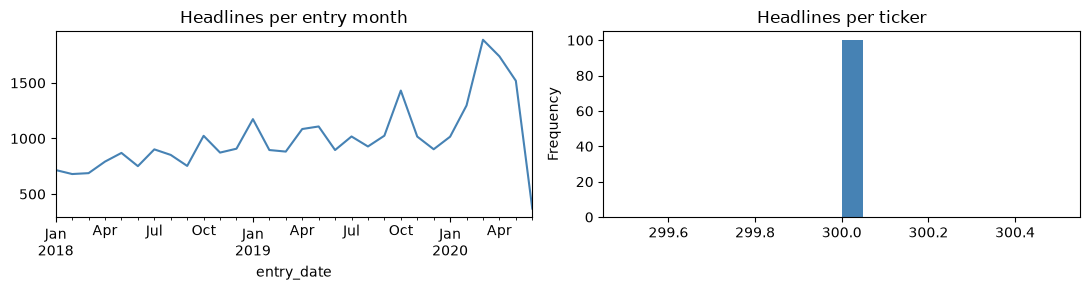

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ds.groupby(ds['entry_date'].dt.to_period('M')).size().plot(ax=ax[0], color='steelblue'); ax[0].set_title('Headlines per entry month')
ds['ticker'].value_counts().plot.hist(bins=20, ax=ax[1], color='steelblue'); ax[1].set_title('Headlines per ticker')
plt.tight_layout(); plt.show()

## 8. What does the conservative date-only rule cost?

On the timestamped subset we know the real time, so we can compare the exact rule with the "pretend we only know
the date" rule on the same rows.

In [15]:
known = ds[ds['time_known']].copy()
if len(known):
    exact = [entry_date(t, True) for t in known['published_at']]
    date_only = [entry_date(t, False) for t in known['published_at']]
    shifted = (pd.Series(date_only, index=known.index) != pd.Series(exact, index=known.index))
    print(f'timestamped rows in the sample: {len(known):,} ({len(known) / len(ds):.1%} of the sample)')
    print(f'share whose entry day differs under the date-only rule: {shifted.mean():.1%}')
else:
    print('no timestamped rows in the sample')

timestamped rows in the sample: 409 (1.4% of the sample)
share whose entry day differs under the date-only rule: 87.8%


## 9. Save

Two files, each with a purpose:

- `data/processed/dataset.csv` is what notebooks 02 to 05 read, so none of them has to reload the 1.4M-row raw file.
- `data/raw/news.csv` is the small headline sample on its own. It is the easy thing to upload to Colab for GPU work.

In [16]:
PROCESSED.mkdir(parents=True, exist_ok=True)
ds.to_csv(PROCESSED / 'dataset.csv', index=False)
sample.to_csv(RAW / 'news.csv', index=False)
print('saved', PROCESSED / 'dataset.csv', ds.shape, '|', RAW / 'news.csv', sample.shape)

saved ..\data\processed\dataset.csv (30000, 7) | ..\data\raw\news.csv (30000, 4)


## Takeaways (numbers copied from the outputs above)

**What we built.** 1.41M raw rows -> 252,529 after window / duplicate / roundup cleaning -> a sample of
**30,000 headlines, 100 tickers, 636 trading days** (2018-01-02 to 2020-06-10). No rows were lost in the price join.
All integrity checks passed (no weekend entries, no entry before the news date, three returns recomputed by hand).

**Findings that shape the rest of the project**

1. **Almost no real timestamps.** 96% of the raw file is date-only, and only 409 of the 30,000 sampled rows (1.4%) have a
   time. So nearly every row uses the conservative "enter at the next business day's close" rule. That means we test
   whether news predicts the return from **day D+1 close to D+2 close** (post-news drift), not the immediate reaction.
   A null result would therefore **not** prove the LLM misreads news; most of the reaction is already in the price.
2. **Survivorship bias.** 23 of 150 candidate tickers had no Yahoo prices (acquired, delisted or renamed, e.g. BBBY, ATVI, FB).
   The sample only contains companies that survived to today. The universe is also not only single companies: 15 of the
   100 tickers are ETFs (for example QQQ, IWM, XLK, XLF), whose headlines are about markets or sectors, and GOOG and GOOGL
   are the same company counted twice. I did not test whether dropping them changes anything.
3. **Returns look sensible but are fat tailed.** Mean abnormal return -0.0001 (t = -0.68, p = 0.50, consistent with 0),
   daily std 2.15%, excess kurtosis 94.5. The largest moves (INO in March 2020, PCG in January 2019) are consistent
   with known events but I have not verified each one. Use rank-based IC, and winsorize before any mean-based backtest.
4. **The labels are not 50/50.** P(stock beats SPY) = 49.16% (binomial p = 0.004), so "always predict down" scores **50.84%**.
   That, not 50%, is the accuracy baseline a model must beat.
5. **Power is limited.** The smallest accuracy edge we could reliably detect is about 0.8 points if all rows were independent
   and about 1.0 point using distinct ticker-days (18,126). Real power is lower still because stocks move together
   on the same day. An honest outcome could be "no detectable edge".

**Known issues not fixed yet**

- Winter timestamps are all labelled `-04:00`. Checked: this is a true fixed offset and our `US/Eastern` conversion handles it
  (see the check in section 2). Not a problem.
- **Many headlines are tagged to several tickers.** The roundup filter only removes headlines on 20 or more tickers. Measured on
  the sample: 46% of the test rows (3,503 of 7,542) have a headline the source tags to two or more tickers, 35% to three or more.
  Some are market roundups, some are about one company but tagged to its peers (a Walmart earnings preview under another retailer).
  The main analysis keeps them. Notebook 05 reruns the key numbers on single-ticker headlines only as a robustness check; that
  definition was fixed before looking at any result.
- `evaluate.direction_acc` compares against the sign of the return, so the 50.84% baseline above must be reported next to it.